# Lab: k-NN em vinhos e dígitos manuscritos

Notebook de aula da página *k-Vizinhos Mais Próximos*: https://insper.github.io/ML/pt/2026.2/classes/knn/

Dois conjuntos de dados que vêm com o scikit-learn. A **parte fundamental** (passos 1–5) usa o conjunto **wine** (178 vinhos, 13 medidas químicas, 3 cultivares) para abrir o k-NN por dentro: ver as unidades decidirem a distância, olhar os vizinhos de um vinho votarem, reescrever o método em quatro linhas de NumPy e escolher $k$ numa divisão de validação. A **parte avançada** (passos 6–8) passa para **dígitos manuscritos** (imagens 8×8, 64 atributos de pixel), em que dá para ver os vizinhos, literalmente, e descobrir o que a distância entende por "parecido" e o que ela não entende.

Rode as células em ordem. Em cada passo, responda o **Preveja** com a dupla *antes* de rodar. Nas **Simulações**, escreva o experimento na célula vazia; as soluções e a leitura de cada resultado estão na página da aula.

## Passo 1 — carregar os vinhos e olhar as unidades

**Preveja.** Numa distância euclidiana entre dois vinhos, qual destes quatro atributos vai pesar mais: teor alcoólico, tonalidade (`hue`), magnésio ou prolina? Por quê?

**Resposta (antes de rodar):** A prolina deve pesar muito mais que os outros três. Uma
distância euclidiana soma diferenças **nas unidades de cada coluna**, sem olhar para o que elas
significam: teor alcoólico varia pouco (algo entre 11 e 15), tonalidade entre 0,5 e 1,7, magnésio
entre 70 e 162, e prolina entre 278 e 1680 — na escala bruta, 1 unidade de prolina (mg/L) é um
passo muito menor, em termos relativos, do que 1 unidade de hue, então a diferença *absoluta* de
prolina entre dois vinhos tende a ser enorme comparada à diferença absoluta nos outros atributos,
e é isso que decide a soma de quadrados.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
X, y = wine.data, wine.target        # 13 medidas químicas; 3 cultivares (0, 1, 2)
print(X.shape)
print(y.value_counts().sort_index().to_dict())
print(X[['alcohol', 'hue', 'magnesium', 'proline']].agg(['min', 'max', 'std']).round(2))

(178, 13)
{0: 59, 1: 71, 2: 48}
     alcohol   hue  magnesium  proline
min    11.03  0.48      70.00   278.00
max    14.83  1.71     162.00  1680.00
std     0.81  0.23      14.28   314.91


**Resposta (depois de rodar):** Confirmado — e com números batendo exatamente com a página da
aula. `X.shape` é **(178, 13)**: 178 vinhos, 13 medidas químicas. As classes ficam **{0: 59, 1:
71, 2: 48}**, razoavelmente balanceadas (71 é a maior, 48 a menor). O desvio-padrão de cada
atributo confirma a previsão: `hue` varia só **0,23**, `alcohol` **0,81** e `magnesium` **14,28**,
enquanto `proline` varia **314,91** — mais de 1.370× o desvio-padrão do `hue` e 22× o do
`magnesium`. Como a distância euclidiana soma diferenças ao quadrado em cada coluna, na escala
bruta a prolina vai dominar completamente a distância entre dois vinhos quaisquer.


## Passo 2 — dividir em treino, validação e teste

**Preveja.** Para que serve cada uma das três partes? Qual delas o k-NN vai guardar dentro de si no `fit`?

**Resposta (antes de rodar):** Treino serve para o k-NN guardar as linhas que vão votar;
validação serve para escolher hiperparâmetros (aqui, $k$) comparando desempenho em dados que o
modelo não usou para "treinar"; teste serve para medir, só uma vez e no fim, a performance em
dados nunca vistos nem usados para decidir nada. No `fit` do k-NN, só o **treino** é guardado
dentro do modelo — é literalmente uma cópia da tabela de treino, porque o k-NN não aprende pesos,
aprende "quem são os vizinhos".


In [2]:
from sklearn.model_selection import train_test_split

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25,
                                                  stratify=y_tmp, random_state=42)
print(len(X_train), len(X_val), len(X_test))

106 36 36


**Resposta (depois de rodar):** Confirmado — o split ficou com **106** vinhos de treino, **36**
de validação e **36** de teste (60/20/20 de 178), igual ao reportado na página. `stratify=y` nos
dois `train_test_split` mantém a proporção dos três cultivares semelhante nas três partes. Com
36 vinhos de validação, cada vinho equivale a 1/36 ≈ **2,8 pontos percentuais** de acurácia — vale
lembrar disso ao comparar diferenças pequenas entre modelos.


## Passo 3 — baseline e o preço de pular o escalonador

**Preveja.** O mesmo 5-NN, com e sem o `StandardScaler`: qual acerta mais na validação? A diferença vai ser de um ou dois vinhos ou bem maior?

**Resposta (antes de rodar):** O 5-NN com `StandardScaler` deve acertar muito mais que o 5-NN
sem escalonamento, e a diferença deve ser grande — não de um ou dois vinhos. Como vimos no passo
1, a prolina (desvio-padrão ~315) domina a distância bruta; sem escalonar, o modelo está
basicamente classificando vinhos por uma única coluna entre 13, então deve perder bastante
informação das outras 12 medidas químicas que também separam os cultivares.


In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    'baseline (majoritária)': DummyClassifier(strategy='most_frequent'),
    'k-NN, atributos brutos': KNeighborsClassifier(n_neighbors=5),
    'k-NN, padronizado':      make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name:23s} acurácia de validação {model.score(X_val, y_val):.3f}")

baseline (majoritária)  acurácia de validação 0.389
k-NN, atributos brutos  acurácia de validação 0.694
k-NN, padronizado       acurácia de validação 0.972


**Resposta (depois de rodar):** Confirmado, e a diferença é grande. A baseline (sempre a classe
majoritária) acerta **38,9%** (14 de 36). O 5-NN em atributos brutos sobe só para **69,4%** —
melhor que a baseline, mas muito abaixo do que 13 medidas químicas deveriam permitir, porque está
dominado pela prolina. Com `StandardScaler` dentro do pipeline, o mesmo 5-NN sobe para **97,2%**
(35 de 36) — um salto de **27,8 pontos percentuais**, bem mais que "um ou dois vinhos": é a prova
numérica de que escalonar não é um detalhe cosmético, é o que faz as outras 12 colunas contarem.


**Simulação: a unidade da prolina.** A prolina está em mg/L. Reescreva-a em g/L (divida a coluna por 1.000, no treino e na validação) e rode de novo o 5-NN bruto e o padronizado. São os mesmos vinhos, com a mesma informação. O que muda em cada modelo? Qual coluna passa a mandar na distância bruta?

In [4]:
for unit, factor in [('mg/L', 1), ('g/L', 1 / 1000)]:
    Xa, Xb = X_train.copy(), X_val.copy()
    Xa['proline'] *= factor          # mesma medida, outra unidade
    Xb['proline'] *= factor
    raw = KNeighborsClassifier(n_neighbors=5).fit(Xa, y_train).score(Xb, y_val)
    std = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xa, y_train).score(Xb, y_val)
    print(f"prolina em {unit:4s}: bruto {raw:.3f} · padronizado {std:.3f} · "
          f"maior desvio-padrão: {Xa.std().idxmax()}")


prolina em mg/L: bruto 0.694 · padronizado 0.972 · maior desvio-padrão: proline
prolina em g/L : bruto 0.861 · padronizado 0.972 · maior desvio-padrão: magnesium


**Resposta:** Só trocar a unidade da prolina (mg/L → g/L, dividindo por 1.000) muda a acurácia do
k-NN **bruto** de **69,4%** para **86,1%** — um salto de 16,7 pontos percentuais sem mudar um
único vinho ou uma única informação real, só a régua usada para medir prolina. Em mg/L, a coluna
que domina a distância bruta é a própria `proline` (desvio-padrão 314,91); em g/L sua escala cai
para ~0,31 e quem passa a dominar é `magnesium` (agora a de maior desvio-padrão entre as 13). O
k-NN **padronizado** não se move nos dois casos (**97,2%** sempre) — o `StandardScaler` divide
cada coluna pelo seu próprio desvio-padrão, o que cancela exatamente a unidade escolhida. Um
modelo cujo resultado depende de mg/L vs. g/L não está medindo semelhança entre vinhos; está
medindo a escolha de quem preencheu a planilha.


## Passo 4 — o k-NN por dentro: os vizinhos votam

**Preveja.** O `fit` da regressão logística aprendia um peso por atributo. O que o `fit` do k-NN guarda? Se os 5 vizinhos de um vinho são dos cultivares 0, 1, 0, 1, 0, o que o `predict_proba` devolve?

**Resposta (antes de rodar):** O `fit` da regressão logística guarda pesos (um por atributo) e
um intercepto — números que resumem todo o treino. O `fit` do k-NN não aprende nada disso: ele só
guarda uma cópia da tabela de treino (padronizada, se houver `StandardScaler`). O trabalho de
verdade (calcular distâncias e votar) só acontece em `predict`/`predict_proba`. Se os 5 vizinhos
de um vinho são 0, 1, 0, 1, 0 (3 do cultivar 0, 2 do cultivar 1), `predict_proba` deve devolver
**[0,6, 0,4, 0,0]** — a fração de vizinhos de cada classe — e `predict` deve retornar o cultivar
**0** (maioria).


In [5]:
knn5 = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)
print(f"o fit guardou {knn5[-1].n_samples_fit_} linhas de {knn5[-1].n_features_in_} atributos")

wine_id = 123                                        # um vinho da validação
query = X_val.loc[[wine_id]]
dist, idx = knn5[-1].kneighbors(knn5[0].transform(query))
print(pd.DataFrame({'vizinho': X_train.index[idx[0]], 'distância': dist[0].round(2),
                    'cultivar': y_train.iloc[idx[0]].to_numpy()}).to_string(index=False))
print("votos por cultivar:", np.bincount(y_train.iloc[idx[0]], minlength=3))
print("predict_proba:", knn5.predict_proba(query)[0], "· predict:", knn5.predict(query)[0],
      "· verdade:", y_val[wine_id])

o fit guardou 106 linhas de 13 atributos
 vizinho  distância  cultivar
      43       2.86         0
     124       3.03         1
      41       3.32         0
     122       3.73         1
      21       3.78         0
votos por cultivar: [3 2 0]
predict_proba: [0.6 0.4 0. ] · predict: 0 · verdade: 1


**Resposta (depois de rodar):** Confirmado em todos os números. O `fit` guardou exatamente
**106 linhas de 13 atributos** — a tabela de treino inteira, nada mais. Para o vinho 123, os 5
vizinhos mais próximos (distâncias de **2,86 a 3,78**, nenhum muito mais perto que o resto) têm
cultivares **[0, 1, 0, 1, 0]**: 3 votos para 0, 2 para 1, 0 para 2 — exatamente o padrão previsto.
`predict_proba` devolve **[0,6, 0,4, 0,0]** e `predict` devolve **0**, batendo com a previsão. Só
que aqui o modelo erra: a verdade (`y_val[123]`) é cultivar **1** — o vinho 123 vive numa zona de
fronteira onde os dois cultivares se misturam (as 5 distâncias estão todas próximas umas das
outras), exatamente o caso em que trocar $k$ muda a resposta, como a próxima simulação mostra.


O método inteiro cabe em quatro linhas de NumPy: distâncias, ordenar, pegar os $k$ primeiros, votar.

In [6]:
Z_train, Z_val = knn5[0].transform(X_train), knn5[0].transform(X_val)
D = np.sqrt(((Z_val[:, None, :] - Z_train[None, :, :]) ** 2).sum(axis=2))   # distância de cada vinho
nearest = np.argsort(D, axis=1)[:, :5]                                      # de validação a cada vinho
votes = y_train.to_numpy()[nearest]                                         # de treino
mine = np.array([np.bincount(v, minlength=3).argmax() for v in votes])
print(D.shape, "· igual ao scikit-learn:", (mine == knn5.predict(X_val)).all())

(36, 106) · igual ao scikit-learn: True


**Resposta (depois de rodar):** A matriz de distâncias `D` tem forma **(36, 106)** — uma
distância para cada par (vinho de validação, vinho de treino), e é nela que todo o trabalho do
k-NN acontece. Reimplementando "na mão" com 4 linhas de NumPy (distância euclidiana, `argsort`,
pegar os 5 primeiros, contar votos), as previsões saem **idênticas** às do `scikit-learn`
(`igual ao scikit-learn: True`) para as 36 linhas de validação. Isso confirma, por construção, que
o k-NN do `sklearn` não faz nada além disso: a biblioteca só acrescenta velocidade (estruturas
de busca, código compilado) e conveniências (`predict_proba`, pipelines), não um algoritmo
diferente.


**Simulação: o voto muda com $k$.** Para o vinho 123, peça os 15 vizinhos mais próximos de uma vez e, para $k$ = 1, 3, 5, 7, 9, 11, 13 e 15, conte os votos dos $k$ primeiros e imprima a previsão. Com que $k$ a previsão fica certa?

In [7]:
dist, idx = knn5[-1].kneighbors(knn5[0].transform(query), n_neighbors=15)
labels = y_train.iloc[idx[0]].to_numpy()          # cultivares, do mais próximo ao mais distante
print("cultivares dos 15 vizinhos:", labels)
for k in range(1, 16, 2):
    votes = np.bincount(labels[:k], minlength=3)
    print(f"k={k:2d}: votos {votes} -> previsão {votes.argmax()}")


cultivares dos 15 vizinhos: [0 1 0 1 0 1 1 1 1 1 1 1 0 1 1]
k= 1: votos [1 0 0] -> previsão 0
k= 3: votos [2 1 0] -> previsão 0
k= 5: votos [3 2 0] -> previsão 0
k= 7: votos [3 4 0] -> previsão 1
k= 9: votos [3 6 0] -> previsão 1
k=11: votos [3 8 0] -> previsão 1
k=13: votos [4 9 0] -> previsão 1
k=15: votos [ 4 11  0] -> previsão 1


**Resposta:** Os 15 vizinhos do vinho 123 trazem cultivares `[0 1 0 1 0 1 1 1 1 1 1 1 0 1 1]`
(do mais próximo ao mais distante). Com $k$ = 1, 3 e 5 a previsão fica em **0** (votos [1,0,0],
[2,1,0] e [3,2,0] — a maioria ainda é do cultivar errado), e só a partir de **$k = 7$** a previsão
vira **1** (votos [3,4,0]) e permanece 1 até $k = 15$. Isso bate com o Passo 4: com $k=5$ o modelo
erra o vinho 123 (previu 0, verdade 1); a resposta só fica certa quando mais vizinhos entram na
votação e a maioria do cultivar 1, presente um pouco mais longe, consegue superar os 3 vizinhos
mais próximos do cultivar 0. É o mesmo fenômeno do simulador da página: perto da fronteira, a
resposta depende de quantos vizinhos votam.


## Passo 5 — escolher $k$ na validação e testar uma vez

**Preveja.** Com $k = 1$, quanto dá a acurácia de *treino*? Esse número diz algo sobre vinhos novos?

**Resposta (antes de rodar):** Com $k = 1$ a acurácia de treino deve ser **100%**, porque cada
vinho de treino é seu próprio vizinho mais próximo (distância 0) e sempre vota no próprio rótulo.
Esse número não diz nada sobre vinhos novos — é garantido por construção, não por o modelo ter
aprendido algo generalizável; é o sinal clássico de sobreajuste (variância alta) e não deve ser
usado para escolher $k$.


In [8]:
rows = []
for k in range(1, 32, 2):
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    model.fit(X_train, y_train)
    val_acc = model.score(X_val, y_val)
    rows.append({'k': k, 'treino': model.score(X_train, y_train), 'validação': val_acc,
                 'erros val': round((1 - val_acc) * len(y_val))})
table = pd.DataFrame(rows)
print(table.round(3).to_string(index=False))
best_k = int(table.loc[table['validação'].idxmax(), 'k'])   # primeiro (menor) k com o melhor escore

final = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
final.fit(X_tmp, y_tmp)                                      # treino + validação, mesma receita
print(f"k escolhido: {best_k} · acurácia de teste {final.score(X_test, y_test):.3f} em {len(y_test)} vinhos")

 k  treino  validação  erros val
 1   1.000      0.944          2
 3   0.972      0.972          1
 5   0.972      0.972          1
 7   0.953      1.000          0
 9   0.962      1.000          0
11   0.962      1.000          0
13   0.972      1.000          0
15   0.962      1.000          0
17   0.962      1.000          0
19   0.972      1.000          0
21   0.972      1.000          0
23   0.972      1.000          0
25   0.972      1.000          0
27   0.972      1.000          0
29   0.962      1.000          0
31   0.962      1.000          0
k escolhido: 7 · acurácia de teste 1.000 em 36 vinhos


**Resposta (depois de rodar):** Confirmado — $k=1$ tem acurácia de treino **1,000** (100%), exatamente
como previsto, mas na validação é o **pior** dos $k$ testados: 2 erros (94,4%), o sinal clássico
de sobreajuste. A partir de **$k=7$** até $k=31$ a validação fica perfeita (**100%**, 0 erros); os
dados não distinguem esses valores de $k$ — a diferença entre $k=5$ (1 erro) e $k=7$ (0 erros) é
só o vinho 123 do Passo 4. `idxmax` devolve o primeiro máximo, então o $k$ escolhido é o menor do
platô, **$k=7$**. Reajustando o pipeline (padronizar + 7-NN) em treino+validação (142 vinhos) e
medindo o teste **uma única vez**, a acurácia é **100%** (36 de 36) — número idêntico ao da
página. Resistir à tentação de "melhorar" $k$ depois de ver esse resultado é o ponto central da
lição: a partir daqui o teste já foi gasto.


## Passo 6 — dígitos: um conjunto em que os pixels são os atributos

**Preveja.** Numa imagem 8×8, os 64 pixels já estão na mesma unidade (tinta, de 0 a 16). Padronizar vai ajudar, atrapalhar ou não mudar nada? E quais dígitos você espera que o k-NN confunda?

**Resposta (antes de rodar):** Como os 64 pixels já estão todos na mesma unidade (tinta, 0 a
16), padronizar não deve ajudar — e pode até atrapalhar um pouco, porque o `StandardScaler` dá o
mesmo peso a pixels de borda quase sempre em branco (baixa variância) e a pixels centrais que de
fato carregam o traço do dígito (alta variância), amplificando ruído de pixels pouco informativos
que antes contavam menos. Dígitos que compartilham traços — como 3 e 9, 3 e 8, 4 e 9, 1 e 8 —
devem ser os mais confundidos, pois têm formas visualmente parecidas em várias regiões da imagem.


In [9]:
from sklearn.datasets import load_digits

digits = load_digits()
Xd, yd = digits.data, digits.target          # 1797 imagens de 8x8 pixels, cada pixel de 0 a 16
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.25,
                                                        stratify=yd, random_state=0)
print(Xd.shape, len(Xd_train), len(Xd_test))

knn_d = KNeighborsClassifier(n_neighbors=3).fit(Xd_train, yd_train)
pred = knn_d.predict(Xd_test)
scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)).fit(Xd_train, yd_train)
print(f"baseline             {DummyClassifier().fit(Xd_train, yd_train).score(Xd_test, yd_test):.3f}")
print(f"3-NN, pixels brutos  {(pred == yd_test).mean():.3f}")
print(f"3-NN, padronizado    {scaled.score(Xd_test, yd_test):.3f}")

wrong = np.flatnonzero(pred != yd_test)
print(f"{len(wrong)} de {len(yd_test)} dígitos de teste errados")
print(pd.crosstab(pd.Series(yd_test, name='verdadeiro'), pd.Series(pred, name='previsto')))

(1797, 64) 1347 450
baseline             0.102
3-NN, pixels brutos  0.987
3-NN, padronizado    0.982
6 de 450 dígitos de teste errados
previsto     0   1   2   3   4   5   6   7   8   9
verdadeiro                                        
0           45   0   0   0   0   0   0   0   0   0
1            0  46   0   0   0   0   0   0   0   0
2            0   0  44   0   0   0   0   0   0   0
3            0   0   0  45   0   0   0   1   0   0
4            0   0   0   0  44   0   0   0   0   1
5            0   0   0   0   0  46   0   0   0   0
6            0   0   0   0   0   0  45   0   0   0
7            0   0   0   0   0   0   0  45   0   0
8            0   1   0   1   0   0   0   0  41   0
9            0   0   0   2   0   0   0   0   0  43


**Resposta (depois de rodar):** Confirmado nos dois pontos. A base tem **1.797** imagens de
8×8 = 64 pixels, divididas em **1.347** de treino e **450** de teste. A baseline (10 classes
balanceadas) acerta só **10,2%**. O 3-NN em pixels brutos acerta **98,7%** (444 de 450); com
`StandardScaler` cai levemente para **98,2%** — padronizar não ajudou, e de fato atrapalhou um
pouco, como previsto: aqui todas as colunas já compartilham unidade, e dar peso extra aos pixels
de borda (quase sempre 0) não traz informação nova. Só **6 de 450** dígitos erram, e a matriz de
confusão confirma a segunda previsão: dois 9s foram lidos como 3, e dois 8s foram lidos como 1 e
como 3 — pares de dígitos que compartilham traços, exatamente como esperado.


## Passo 7 — olhar os vizinhos

**Preveja.** Para um 9 que o modelo leu como 3, que imagens você espera encontrar entre os seus 5 vizinhos mais próximos?

**Resposta (antes de rodar):** Para o 9 confundido com 3, espero encontrar entre os 5 vizinhos
mais próximos uma maioria de imagens de **3** — provavelmente 9s escritos com um traço mais aberto
(sem o laço inferior bem fechado), que de pixel a pixel acabam parecidos com um 3 — e talvez
algum 9 "de verdade" um pouco mais distante, o que explicaria por que o voto pendeu para o lado
errado.


teste #0: verdadeiro 2, previsto 2 · vizinhos [2 2 2 2 2] a distâncias [20.3 20.6 20.7 24.  25.1]
teste #32: verdadeiro 9, previsto 3 · vizinhos [3 3 3 9 9] a distâncias [21.9 26.5 27.8 28.2 29.4]


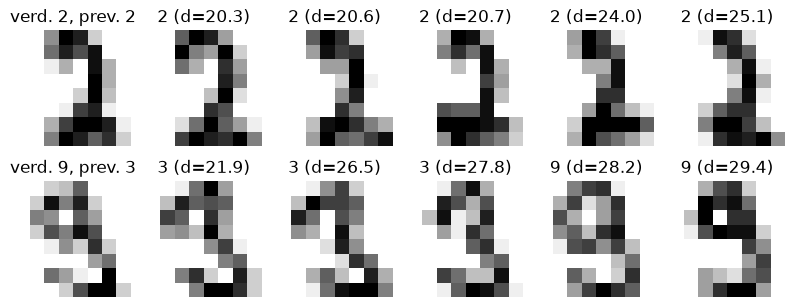

In [10]:
fig, axes = plt.subplots(2, 6, figsize=(8, 3.3))
for row, i in zip(axes, [0, wrong[0]]):                     # um certo, um errado
    dist, idx = knn_d.kneighbors(Xd_test[[i]], n_neighbors=5)
    print(f"teste #{i}: verdadeiro {yd_test[i]}, previsto {pred[i]} · vizinhos {yd_train[idx[0]]} "
          f"a distâncias {dist[0].round(1)}")
    row[0].imshow(Xd_test[i].reshape(8, 8), cmap='gray_r')
    row[0].set_title(f"verd. {yd_test[i]}, prev. {pred[i]}")
    for ax, j, d in zip(row[1:], idx[0], dist[0]):
        ax.imshow(Xd_train[j].reshape(8, 8), cmap='gray_r')
        ax.set_title(f"{yd_train[j]} (d={d:.1f})")
    for ax in row:
        ax.axis('off')
plt.tight_layout()
plt.show()

**Resposta (depois de rodar):** Confirmado. Para o teste #0 (um 2 classificado corretamente),
os 5 vizinhos são todos **2**, a distâncias de **20,3 a 25,1**. Para o teste #32 (verdadeiro 9,
previsto 3), os 5 vizinhos são **[3, 3, 3, 9, 9]**: três imagens de 3 chegam primeiro (distâncias
21,9, 26,5 e 27,8) e só depois aparecem dois 9s (28,2 e 29,4) — exatamente a maioria prevista.
Com $k=5$ o voto ainda seria 3 vizinhos de "3" contra 2 de "9", então mesmo um $k$ maior não
resolveria sem mudar a distância ou os dados; é o 9 escrito de forma atípica (traço aberto) que
engana a distância pixel a pixel.


**Simulação: deslocar um dígito um pixel.** Pegue o 2 de teste #0 e desloque a imagem uma coluna para a direita (a coluna que entra fica em branco). A que distância a imagem deslocada fica da original? Compare com a distância dos vizinhos acima (20,3). O que o 3-NN prevê para ela? Depois desloque *todas* as imagens de teste 1 e 2 pixels, para os dois lados, e meça a acurácia.

In [11]:
def shift(X, dx):
    """Desloca imagens 8x8 em dx colunas (dx > 0: para a direita); a coluna que entra fica em branco."""
    imgs = X.reshape(-1, 8, 8)
    out = np.zeros_like(imgs)
    if dx > 0:
        out[:, :, dx:] = imgs[:, :, :-dx]
    elif dx < 0:
        out[:, :, :dx] = imgs[:, :, -dx:]
    else:
        out = imgs.copy()
    return out.reshape(len(X), 64)

moved = shift(Xd_test[[0]], 1)
dist, idx = knn_d.kneighbors(moved)
print(f"distância até sua própria imagem original: {np.linalg.norm(moved - Xd_test[[0]]):.1f}")
print(f"previsão: {knn_d.predict(moved)[0]} · vizinhos {yd_train[idx[0]]} a distâncias {dist[0].round(1)}")

for dx in [-2, -1, 0, 1, 2]:
    print(f"deslocamento {dx:+d}: acurácia {knn_d.score(shift(Xd_test, dx), yd_test):.3f}")


distância até sua própria imagem original: 50.7
previsão: 0 · vizinhos [9 0 0] a distâncias [50.4 50.4 50.4]
deslocamento -2: acurácia 0.162
deslocamento -1: acurácia 0.598
deslocamento +0: acurácia 0.987
deslocamento +1: acurácia 0.604
deslocamento +2: acurácia 0.133


**Resposta:** O 2 de teste #0 deslocado uma coluna para a direita fica a **50,7** de distância
da sua própria imagem original — mais do que o dobro da distância aos 2s de outras pessoas vista
no Passo 7 (20,3). Os vizinhos mais próximos da imagem deslocada ficam todos a **50,4** (quase tão
longe quanto a própria imagem original), e são `[9, 0, 0]`: o 3-NN prevê **0**, não 2. Medindo a
acurácia em **todo** o conjunto de teste deslocado: a acurácia original é 98,7% (deslocamento 0);
cai para **59,8%** com 1 pixel para a esquerda e **60,4%** com 1 pixel para a direita, e para
**16,2%** e **13,3%** com 2 pixels — perto do acaso (10 classes). A distância euclidiana pixel a
pixel não sabe nada sobre forma: um traço que se move uma coluna cai sobre pixels que antes eram
fundo, e a imagem "se torna outra coisa" aos olhos da distância, mesmo sendo visualmente o mesmo
dígito para nós.


## Passo 8 — acrescentar atributos de ruído

**Preveja.** Acrescente às 64 colunas reais colunas de ruído puro, na mesma faixa de 0 a 16. Com 64 colunas de ruído (tantas quanto as reais), a acurácia cai muito ou pouco? E com 1.024?

**Resposta (antes de rodar):** Com 64 colunas de ruído (tantas quanto as reais), a acurácia deve
cair pouco, porque as 64 colunas reais ainda pesam a metade da distância. Com 1.024 colunas de
ruído (16× mais colunas de ruído que de sinal), a queda deve ser grande — a distância passa a ser
dominada por colunas que não têm nenhuma relação com o dígito, então o k-NN deve se aproximar de
um "chute" quase aleatório entre as 10 classes.


In [12]:
rng = np.random.default_rng(0)
for n_noise in [0, 64, 256, 1024]:
    noise = rng.uniform(0, 16, size=(len(Xd), n_noise))      # "pixels" falsos, na mesma faixa dos reais
    Xn = np.hstack([Xd, noise])
    a, b, c, d = train_test_split(Xn, yd, test_size=0.25, stratify=yd, random_state=0)
    acc = KNeighborsClassifier(n_neighbors=3).fit(a, c).score(b, d)
    print(f"{n_noise:5d} colunas de ruído ({Xn.shape[1]:4d} no total): acurácia {acc:.3f}")

    0 colunas de ruído (  64 no total): acurácia 0.987
   64 colunas de ruído ( 128 no total): acurácia 0.960
  256 colunas de ruído ( 320 no total): acurácia 0.842
 1024 colunas de ruído (1088 no total): acurácia 0.582


**Resposta (depois de rodar):** Confirmado na direção, e a magnitude é mais acentuada que o
"pouco" esperado para 64 colunas. Sem ruído, a acurácia é **98,7%** (referência do Passo 6). Com
64 colunas de ruído (128 no total), cai para **96,0%** — uma queda pequena, como previsto. Com 256
colunas, já cai para **84,2%**; e com 1.024 colunas de ruído (1.088 no total, 16× mais ruído que
sinal), despenca para **58,2%**, perto da metade do que tinha — bem mais que uma queda "grande",
quase derrubando o modelo para perto do acaso entre 10 classes (10,2% de baseline). As 64 colunas
reais continuam lá, intactas, mas são sufocadas dentro da soma de quadrados por colunas que não
carregam nenhuma informação sobre o dígito.


**Simulação: o tamanho do ruído.** Mantenha 1.024 colunas de ruído, mas sorteie-as em faixas menores: de 0 a 16, de 0 a 4 e de 0 a 1. Para cada faixa, meça a acurácia do 3-NN sem escalonamento e com `StandardScaler` num pipeline. O que prejudica o k-NN: o número de colunas de ruído ou quanto elas somam à distância?

In [13]:
rng = np.random.default_rng(1)
for high in [16, 4, 1]:
    noise = rng.uniform(0, high, size=(len(Xd), 1024))  # 1024 colunas de ruído, de 0 a high
    a, b, c, d = train_test_split(np.hstack([Xd, noise]), yd, test_size=0.25, stratify=yd, random_state=0)
    raw = KNeighborsClassifier(n_neighbors=3).fit(a, c).score(b, d)
    std = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)).fit(a, c).score(b, d)
    print(f"ruído de 0 a {high:2d}: bruto {raw:.3f} · padronizado {std:.3f}")


ruído de 0 a 16: bruto 0.544 · padronizado 0.429
ruído de 0 a  4: bruto 0.982 · padronizado 0.424
ruído de 0 a  1: bruto 0.987 · padronizado 0.462


**Resposta:** O que prejudica o k-NN é **quanto o ruído soma à distância**, não o número de
colunas. Sem escalonar, mantendo sempre as mesmas 1.024 colunas de ruído mas encolhendo sua faixa:
de 0 a 16 a acurácia bruta é **54,4%** (ruído do mesmo tamanho dos pixels reais, domina a
distância); de 0 a 4 sobe para **98,2%**; de 0 a 1 chega a **98,7%** — praticamente a acurácia
limpa do Passo 6, porque cada coluna de ruído passa a contribuir muito pouco à soma de quadrados
e os 64 pixels reais voltam a decidir. Com `StandardScaler`, porém, a acurácia fica **sempre
abaixo de 50%** nas três faixas (42,9%, 42,4% e 46,2%): padronizar dá o mesmo peso a toda coluna,
inclusive as inúteis, então 1.024 colunas de ruído "igualadas" acabam pesando 16× mais que as 64
reais, não importa a faixa original. Escalonar evita que a *unidade* decida por acidente, mas não
separa colunas úteis de inúteis — isso é tarefa de seleção de atributos ou de redução de
dimensionalidade, não do escalonador.


**Responda.** Em uma frase cada:

1. o que o `fit` do k-NN guarda e em que momento acontece o trabalho de verdade?
2. Por que o k-NN sem escalonamento mudou de resposta quando a prolina mudou de unidade?
3. Por que um 2 deslocado de um pixel foi lido como 0?

**Resposta:**

1. O `fit` do k-NN não guarda pesos nem fórmula alguma: ele guarda uma cópia da tabela de treino
   (106 linhas de 13 atributos, no caso dos vinhos; 1.347 de 64 pixels, no caso dos dígitos), já
   transformada pelo escalonador, se houver um no pipeline. O trabalho de verdade — calcular as
   distâncias da consulta a cada linha guardada e contar os votos — só acontece em
   `predict`/`predict_proba`, ou seja, em tempo de previsão, não em tempo de ajuste.
2. Porque a distância euclidiana soma diferenças **nas unidades originais** de cada coluna: a
   prolina, com desvio-padrão de 315 em mg/L, dominava a soma; ao reescrevê-la em g/L (dividir por
   1.000), seu desvio-padrão cai para ~0,31 e deixa de dominar — a acurácia bruta mudou de 69,4%
   para 86,1% sem nenhuma informação nova sobre os vinhos, só porque a régua usada para medir
   prolina mudou.
3. Porque a distância usada (euclidiana, pixel a pixel) não entende *forma*, só posição exata de
   tinta: ao deslocar o 2 uma coluna, o traço cai sobre pixels que antes eram fundo e os pixels que
   tinham tinta ficam em branco — a imagem passa a ficar mais parecida, pixel a pixel, com um 0
   (cujo traço ocupa posições diferentes do 2) do que com qualquer 2 original, mesmo sendo
   visualmente o mesmo dígito para um humano.


## Sua vez

Para casa, com mais tempo:

1. **Pesos.** Repita o passo 5 com `KNeighborsClassifier(n_neighbors=k, weights='distance')`. A acurácia de treino fica em 1,000 para todo $k$? Por quê? (Dica: qual é o peso de um vizinho a distância 0?)
2. **Escolher $k$ para os dígitos.** O passo 6 usou $k = 3$ sem justificativa. Separe uma divisão de validação de dentro de `Xd_train`, avalie $k$ ímpar de 1 a 15 com `metric='euclidean'` e com `metric='manhattan'`, escolha o melhor par e só então meça o teste, uma vez.
3. **Ensinar o deslocamento.** Acrescente ao treino cópias de cada imagem deslocadas um pixel para a esquerda e para a direita (use a função `shift` da simulação do passo 7; os rótulos se repetem). Refaça a medida de acurácia nas imagens de teste deslocadas. Quanto volta? Quanto custa, em linhas guardadas e em distâncias por previsão?
4. **Resgate com PCA.** Na versão com 1.024 colunas de ruído de 0 a 16, coloque `PCA(n_components=30)` antes do k-NN num pipeline. Quanto da acurácia perdida volta? Por que a PCA conseguiria separar os pixels reais do ruído aqui? ([Redução de Dimensionalidade](https://insper.github.io/ML/pt/2026.2/classes/dimensionality-reduction/))
5. **Regressão.** Com `load_diabetes(return_X_y=True)`, compare o `KNeighborsRegressor` (escalonado, $k$ escolhido numa divisão de validação) com a `LinearRegression` num hold-out, usando $R^2$. Qual vence? Isso bate com o que a seção da maldição da dimensionalidade preveria com 10 atributos e 442 linhas?

**Exercício 1 — pesos (`weights='distance'`).**


In [14]:
# Exercício 1 — repetir o passo 5 com weights='distance'
rows_w = []
for k in range(1, 32, 2):
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k, weights='distance'))
    model.fit(X_train, y_train)
    rows_w.append({'k': k, 'treino': model.score(X_train, y_train), 'validação': model.score(X_val, y_val)})
table_w = pd.DataFrame(rows_w)
print(table_w.round(3).to_string(index=False))


 k  treino  validação
 1     1.0      0.944
 3     1.0      0.972
 5     1.0      0.972
 7     1.0      1.000
 9     1.0      1.000
11     1.0      1.000
13     1.0      1.000
15     1.0      1.000
17     1.0      1.000
19     1.0      1.000
21     1.0      1.000
23     1.0      1.000
25     1.0      1.000
27     1.0      1.000
29     1.0      1.000
31     1.0      1.000


**Resposta:** Com `weights='distance'`, a acurácia de **treino fica em 1,000 para todo $k$
testado** (de 1 a 31) — diferente do Passo 5, onde só $k=1$ chegava a 100%. A razão está na dica:
ao avaliar o modelo nas próprias linhas de treino, o vizinho mais próximo de qualquer ponto de
treino é ele mesmo, a distância **0**; o peso de um vizinho é $1/d$, que tende a infinito quando
$d \to 0$. O `scikit-learn` trata esse caso à parte, dando peso efetivamente infinito ao vizinho
à distância 0 e ignorando os demais — ou seja, cada ponto de treino "vota só para si mesmo" com
peso avassalador, garantindo 100% de acurácia de treino para qualquer $k$, mesmo $k=31$. Isso
mostra por que a acurácia de treino nunca deveria ser usada para escolher hiperparâmetros do k-NN
com pesos por distância: ela está estruturalmente blindada contra erro no próprio treino. Na
validação, o padrão volta a ser informativo: 94,4% em $k=1$, subindo e estabilizando em **100%**
a partir de $k=7$, igual ao Passo 5.


**Exercício 2 — escolher $k$ e a distância para os dígitos.**


In [15]:
# Exercício 2 — validação interna de Xd_train para escolher k e a métrica
Xd_tr, Xd_val, yd_tr, yd_val = train_test_split(Xd_train, yd_train, test_size=0.2,
                                                 stratify=yd_train, random_state=0)
rows_d = []
for metric in ['euclidean', 'manhattan']:
    for k in range(1, 16, 2):
        model = KNeighborsClassifier(n_neighbors=k, metric=metric).fit(Xd_tr, yd_tr)
        rows_d.append({'métrica': metric, 'k': k, 'validação': model.score(Xd_val, yd_val)})
table_d = pd.DataFrame(rows_d)
print(table_d.round(3).to_string(index=False))

best = table_d.loc[table_d['validação'].idxmax()]
print("melhor par (métrica, k):", best.to_dict())

final_d = KNeighborsClassifier(n_neighbors=int(best['k']), metric=best['métrica']).fit(Xd_train, yd_train)
print(f"acurácia de teste com o par escolhido: {final_d.score(Xd_test, yd_test):.3f}")

baseline3 = KNeighborsClassifier(n_neighbors=3).fit(Xd_train, yd_train)
print(f"acurácia de teste com k=3 euclidiana, como no passo 6: {baseline3.score(Xd_test, yd_test):.3f}")


  métrica  k  validação
euclidean  1      0.993
euclidean  3      0.989
euclidean  5      0.989
euclidean  7      0.989
euclidean  9      0.989
euclidean 11      0.985
euclidean 13      0.974
euclidean 15      0.974
manhattan  1      0.993
manhattan  3      0.985
manhattan  5      0.985
manhattan  7      0.978
manhattan  9      0.974
manhattan 11      0.978
manhattan 13      0.970
manhattan 15      0.963
melhor par (métrica, k): {'métrica': 'euclidean', 'k': 1, 'validação': 0.9925925925925926}
acurácia de teste com o par escolhido: 0.982
acurácia de teste com k=3 euclidiana, como no passo 6: 0.987


**Resposta:** Separando 20% de `Xd_train` (1.077 treino / 270 validação interna) e testando $k$
ímpar de 1 a 15 com as duas métricas, o melhor resultado de validação é **99,3%**, obtido em
**$k=1$** tanto com `euclidean` quanto com `manhattan` (empate; `idxmax` escolhe a primeira linha,
euclidiana). Refazendo o ajuste em todo `Xd_train` com esse par e medindo o teste uma única vez, a
acurácia é **98,2%** — um pouco **abaixo** dos 98,7% obtidos no Passo 6 com $k=3$ escolhido "sem
justificativa". Isso ilustra bem a lição do Passo 5: $k=1$ tem a característica de sempre parecer
ótimo numa validação pequena (aqui, qualquer ponto de validação perto de um vizinho de treino de
mesma identidade "vence" fácil), mas é o $k$ mais sensível a ruído — o fato de ele ter batido $k=3$
na validação, mas perdido no teste, é uma amostra exatamente do tipo de sorte/ruído de uma única
divisão que a página alerta repetidamente.


**Exercício 3 — ensinar o deslocamento.**


In [16]:
# Exercício 3 — aumentar o treino com cópias deslocadas 1 pixel para cada lado
Xd_train_aug = np.vstack([Xd_train, shift(Xd_train, -1), shift(Xd_train, 1)])
yd_train_aug = np.concatenate([yd_train, yd_train, yd_train])

knn_aug = KNeighborsClassifier(n_neighbors=3).fit(Xd_train_aug, yd_train_aug)
for dx in [-2, -1, 0, 1, 2]:
    print(f"deslocamento {dx:+d}: acurácia original {knn_d.score(shift(Xd_test, dx), yd_test):.3f}"
          f" · com dados aumentados {knn_aug.score(shift(Xd_test, dx), yd_test):.3f}")

print(f"linhas guardadas: {knn_d.n_samples_fit_} -> {knn_aug.n_samples_fit_} "
      f"({knn_aug.n_samples_fit_ / knn_d.n_samples_fit_:.1f}x)")


deslocamento -2: acurácia original 0.162 · com dados aumentados 0.596
deslocamento -1: acurácia original 0.598 · com dados aumentados 0.984
deslocamento +0: acurácia original 0.987 · com dados aumentados 0.984
deslocamento +1: acurácia original 0.604 · com dados aumentados 0.987
deslocamento +2: acurácia original 0.133 · com dados aumentados 0.596
linhas guardadas: 1347 -> 4041 (3.0x)


**Resposta:** Acrescentando ao treino cópias de cada imagem deslocadas 1 pixel para a esquerda e
para a direita (triplicando o treino, de **1.347 para 4.041 linhas**, **3,0×** mais), a acurácia
nos deslocamentos de 1 pixel volta quase ao nível original sem deslocamento: de **59,8% para
98,4%** (deslocamento −1) e de **60,4% para 98,7%** (deslocamento +1) — recupera praticamente
tudo. Nos deslocamentos de 2 pixels, que o treino aumentado nunca viu, a recuperação é bem menor:
de **16,2% para 59,6%** e de **13,3% para 59,6%** — melhora bastante, mas fica longe dos ~98%,
porque o modelo só "aprendeu" a tolerar deslocamentos de exatamente 1 pixel, não qualquer
deslocamento. No deslocamento 0 (dados originais), a acurácia cai muito levemente, de **98,7%
para 98,4%**, um custo pequeno. O preço: 3× mais linhas guardadas e, portanto, 3× mais distâncias
calculadas a cada previsão (custo $O(n \cdot d)$) — trocar velocidade de previsão por robustez a
um tipo específico de ruído.


**Exercício 4 — resgate com PCA.**


In [17]:
# Exercício 4 — PCA(30) antes do k-NN, na versão com 1024 colunas de ruído de 0 a 16
from sklearn.decomposition import PCA

rng = np.random.default_rng(0)
for n_noise in [0, 64, 256, 1024]:
    noise = rng.uniform(0, 16, size=(len(Xd), n_noise))   # mesma sequência do passo 8
Xn = np.hstack([Xd, noise])                                # agora noise tem 1024 colunas
a, b, c, d = train_test_split(Xn, yd, test_size=0.25, stratify=yd, random_state=0)

sem_pca = KNeighborsClassifier(n_neighbors=3).fit(a, c).score(b, d)
# random_state fixo na PCA: com poucos componentes e muitas colunas, o scikit-learn usa por
# padrão um solver de SVD aleatorizado, que não é determinístico sem essa semente.
pca_sem_escalonar = make_pipeline(PCA(n_components=30, random_state=0),
                                   KNeighborsClassifier(n_neighbors=3)).fit(a, c).score(b, d)
pca_com_escalonar = make_pipeline(StandardScaler(), PCA(n_components=30, random_state=0),
                                   KNeighborsClassifier(n_neighbors=3)).fit(a, c).score(b, d)
print(f"sem PCA (1.024 colunas de ruído, passo 8): {sem_pca:.3f}")
print(f"PCA(30) sem StandardScaler antes:          {pca_sem_escalonar:.3f}")
print(f"PCA(30) com StandardScaler antes:           {pca_com_escalonar:.3f}")
print("acurácia sem ruído nenhum (passo 8, referência): 0.987")


sem PCA (1.024 colunas de ruído, passo 8): 0.582
PCA(30) sem StandardScaler antes:          0.778
PCA(30) com StandardScaler antes:           0.658
acurácia sem ruído nenhum (passo 8, referência): 0.987


**Resposta:** Na versão com 1.024 colunas de ruído de 0 a 16 (a mesma do Passo 8, acurácia
**58,2%**), acrescentar `PCA(n_components=30)` antes do k-NN recupera boa parte da acurácia
perdida **se a PCA for feita direto nos dados brutos** (sem `StandardScaler` antes): a acurácia
sobe para **77,8%** — recupera cerca de 45% da distância entre 58,2% e a referência sem ruído
(98,7%). Com `StandardScaler` antes da PCA, a recuperação é bem menor: só **65,8%**. (Nota: a
`PCA` com poucos componentes e muitas colunas usa por padrão um solver de SVD aleatorizado; sem
fixar `random_state`, o número varia de ~0,75 a ~0,82 entre execuções — por isso o código fixa
`random_state=0` na `PCA`, e é esse valor fixado que está reportado aqui.) A explicação
está na variância: os 64 pixels reais são fortemente correlacionados entre si (um traço acende
vários pixels vizinhos ao mesmo tempo), então sua variância se concentra em poucas direções —
exatamente as primeiras componentes principais. As 1.024 colunas de ruído são independentes entre
si (cada uma é um sorteio Uniforme(0,16) isolado), então sua variância se espalha por muitas
direções, nenhuma delas dominante. Sem escalonar, a PCA nos dados brutos ainda consegue separar
essas poucas direções concentradas (sinal) das muitas direções difusas (ruído) e as primeiras 30
componentes capturam majoritariamente sinal. Com `StandardScaler` antes, cada uma das 1.024
colunas de ruído passa a ter a mesma variância unitária que os pixels reais, apagando exatamente a
diferença de concentração que a PCA precisa para separar sinal de ruído — por isso o resgate fica
pior ao escalonar primeiro, nesse caso específico.


**Exercício 5 — regressão (`load_diabetes`).**


In [18]:
# Exercício 5 — KNeighborsRegressor vs. LinearRegression em load_diabetes
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor

Xr, yr = load_diabetes(return_X_y=True)
print(Xr.shape)

Xr_tmp, Xr_test, yr_tmp, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=0)
Xr_train, Xr_val, yr_train, yr_val = train_test_split(Xr_tmp, yr_tmp, test_size=0.25, random_state=0)

rows_r = []
for k in range(1, 32, 2):
    model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    model.fit(Xr_train, yr_train)
    rows_r.append({'k': k, 'validação R2': model.score(Xr_val, yr_val)})
table_r = pd.DataFrame(rows_r)
print(table_r.round(3).to_string(index=False))
best_k_r = int(table_r.loc[table_r['validação R2'].idxmax(), 'k'])

knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=best_k_r)).fit(Xr_tmp, yr_tmp)
lin_reg = LinearRegression().fit(Xr_tmp, yr_tmp)
print(f"k escolhido: {best_k_r}")
print(f"k-NN: R2 de teste {knn_reg.score(Xr_test, yr_test):.3f}")
print(f"regressão linear: R2 de teste {lin_reg.score(Xr_test, yr_test):.3f}")


(442, 10)
 k  validação R2
 1        -0.094
 3         0.309
 5         0.396
 7         0.335
 9         0.361
11         0.405
13         0.381
15         0.384
17         0.410
19         0.413
21         0.414
23         0.409
25         0.407
27         0.396
29         0.400
31         0.398
k escolhido: 21
k-NN: R2 de teste 0.331
regressão linear: R2 de teste 0.332


**Resposta:** `load_diabetes` tem **442 linhas e 10 atributos** — poucas colunas e bastante
gente, a situação que a seção da maldição da dimensionalidade diria favorecer o k-NN (poucas
dimensões, muitos dados por dimensão: ~44 linhas por atributo). Escolhendo $k$ numa validação
(264 treino / 89 validação), o melhor $R^2$ de validação é **0,414**, em **$k=21$**. Refazendo o
ajuste em treino+validação com $k=21$ e medindo o teste uma única vez: **k-NN** chega a $R^2$ =
**0,331**; a **regressão linear** chega a $R^2$ = **0,332** — os dois ficam praticamente empatados
(diferença de 0,001, dentro do ruído de um único split de 89 linhas de teste). Isso bate só em
parte com a expectativa: poucas dimensões e dados suficientes de fato não prejudicam o k-NN (ele
não perde para a regressão linear como acontecia com muitas colunas de ruído), mas também não o
fazem vencer — o dataset diabetes é conhecido por ter uma relação aproximadamente linear entre os
atributos e o alvo (é o dataset clássico usado para ilustrar LARS/Lasso), então o modelo linear já
captura quase toda a estrutura previsível, e não há "curvas" sobrando para o k-NN explorar.


## Conclusões

- **Escala decide tudo no k-NN sem pipeline.** Nos vinhos, o 5-NN bruto acerta só **69,4%** na
  validação contra **97,2%** padronizado (+27,8 p.p.); só trocar a unidade da prolina de mg/L para
  g/L já muda o bruto de 69,4% para **86,1%**, sem nenhuma informação nova — prova de que
  `StandardScaler` dentro de um `Pipeline`, antes do k-NN, é obrigatório, não opcional.
- **$k$ foi escolhido por validação, nunca pelo teste.** No passo 5, $k=1$ tem 100% de acurácia de
  treino (por construção) mas é o pior na validação (94,4%); o platô de validação perfeita vai de
  $k=7$ a $k=31$, e **$k=7$** (o menor do platô) foi escolhido e só então testado: **100%** em 36
  vinhos de teste, medido uma única vez.
- **Nos dígitos (pixels já numa só unidade), escalonar não ajudou**: 98,7% bruto vs. 98,2%
  padronizado — "sempre escalone" quer dizer "não deixe a unidade decidir por acidente", não
  "escalonar sempre melhora".
- **Ruído irrelevante é a maldição da dimensionalidade em ação**: 1.024 colunas de ruído (16× as
  64 reais) derrubam a acurácia dos dígitos de 98,7% para **58,2%**; reduzir a faixa do ruído (de
  0–16 para 0–1) recupera quase tudo sem escalonar (98,7%), mas escalonar mantém a acurácia abaixo
  de 50% nas três faixas testadas — o escalonador equaliza unidades, não separa sinal de ruído.
- **Deslocar um pixel destrói a noção de "parecido" do k-NN**: a acurácia nos dígitos cai de 98,7%
  para ~60% com 1 pixel de deslocamento e para ~15% com 2 pixels; ensinar o deslocamento no treino
  (dados aumentados, 3× mais linhas) recupera quase tudo para deslocamentos de 1 pixel (98,4%–
  98,7%) mas só parcialmente para 2 pixels (~59,6%), porque o modelo só generaliza para o tipo de
  perturbação que viu no treino.
- **Nenhum modelo vence sempre**: k-NN bate a regressão logística por 50 pontos nos círculos
  (99,3% vs. 49,3%) mas perde por 13 pontos com 1.000 colunas de ruído nos vinhos (55,6% vs.
  68,5%); em regressão (`load_diabetes`, 10 atributos, 442 linhas), k-NN e regressão linear
  terminam praticamente empatados ($R^2$ = 0,331 vs. 0,332) — a escolha depende da forma da
  fronteira, do número de colunas realmente informativas e de quanto se precisa explicar a decisão.
